#  First Verification (Computational)

g++ not available, if using conda: `conda install gxx`



1. STEADY STATE
y     1.670937
c     1.285030
i     0.385907
k     6.431781
h     0.808649
w     1.343115
r     0.090928
z     1.000000
b     0.000000
rb    0.030928
ca    0.000000
tb   -0.000000
rp    0.000000
dtype: float64

Maximum steady-state residual: 5.551115123125783e-16

2. CALCULATING JACOBIANS
A: (13, 13)
B: (13, 13)
C: (13, 13)
D: (13, 2)

3. SOLVING MODEL USING GENSYS
Existence and uniqueness: [1, 1, 0]
Gensys return codes: 1 1 0, with the following meaning:
Gensys found a unique solution.
Augmented transition matrix: (16, 16)
Augmented shock matrix: (16, 2)

Original-variable transition block: (13, 13)
Original-variable shock block: (13, 2)

Maximum absolute eigenvalue: 0.950000000000017

4. GENERATING IRFs
Technology IRF: (60, 13)
Risk-premium IRF: (60, 13)


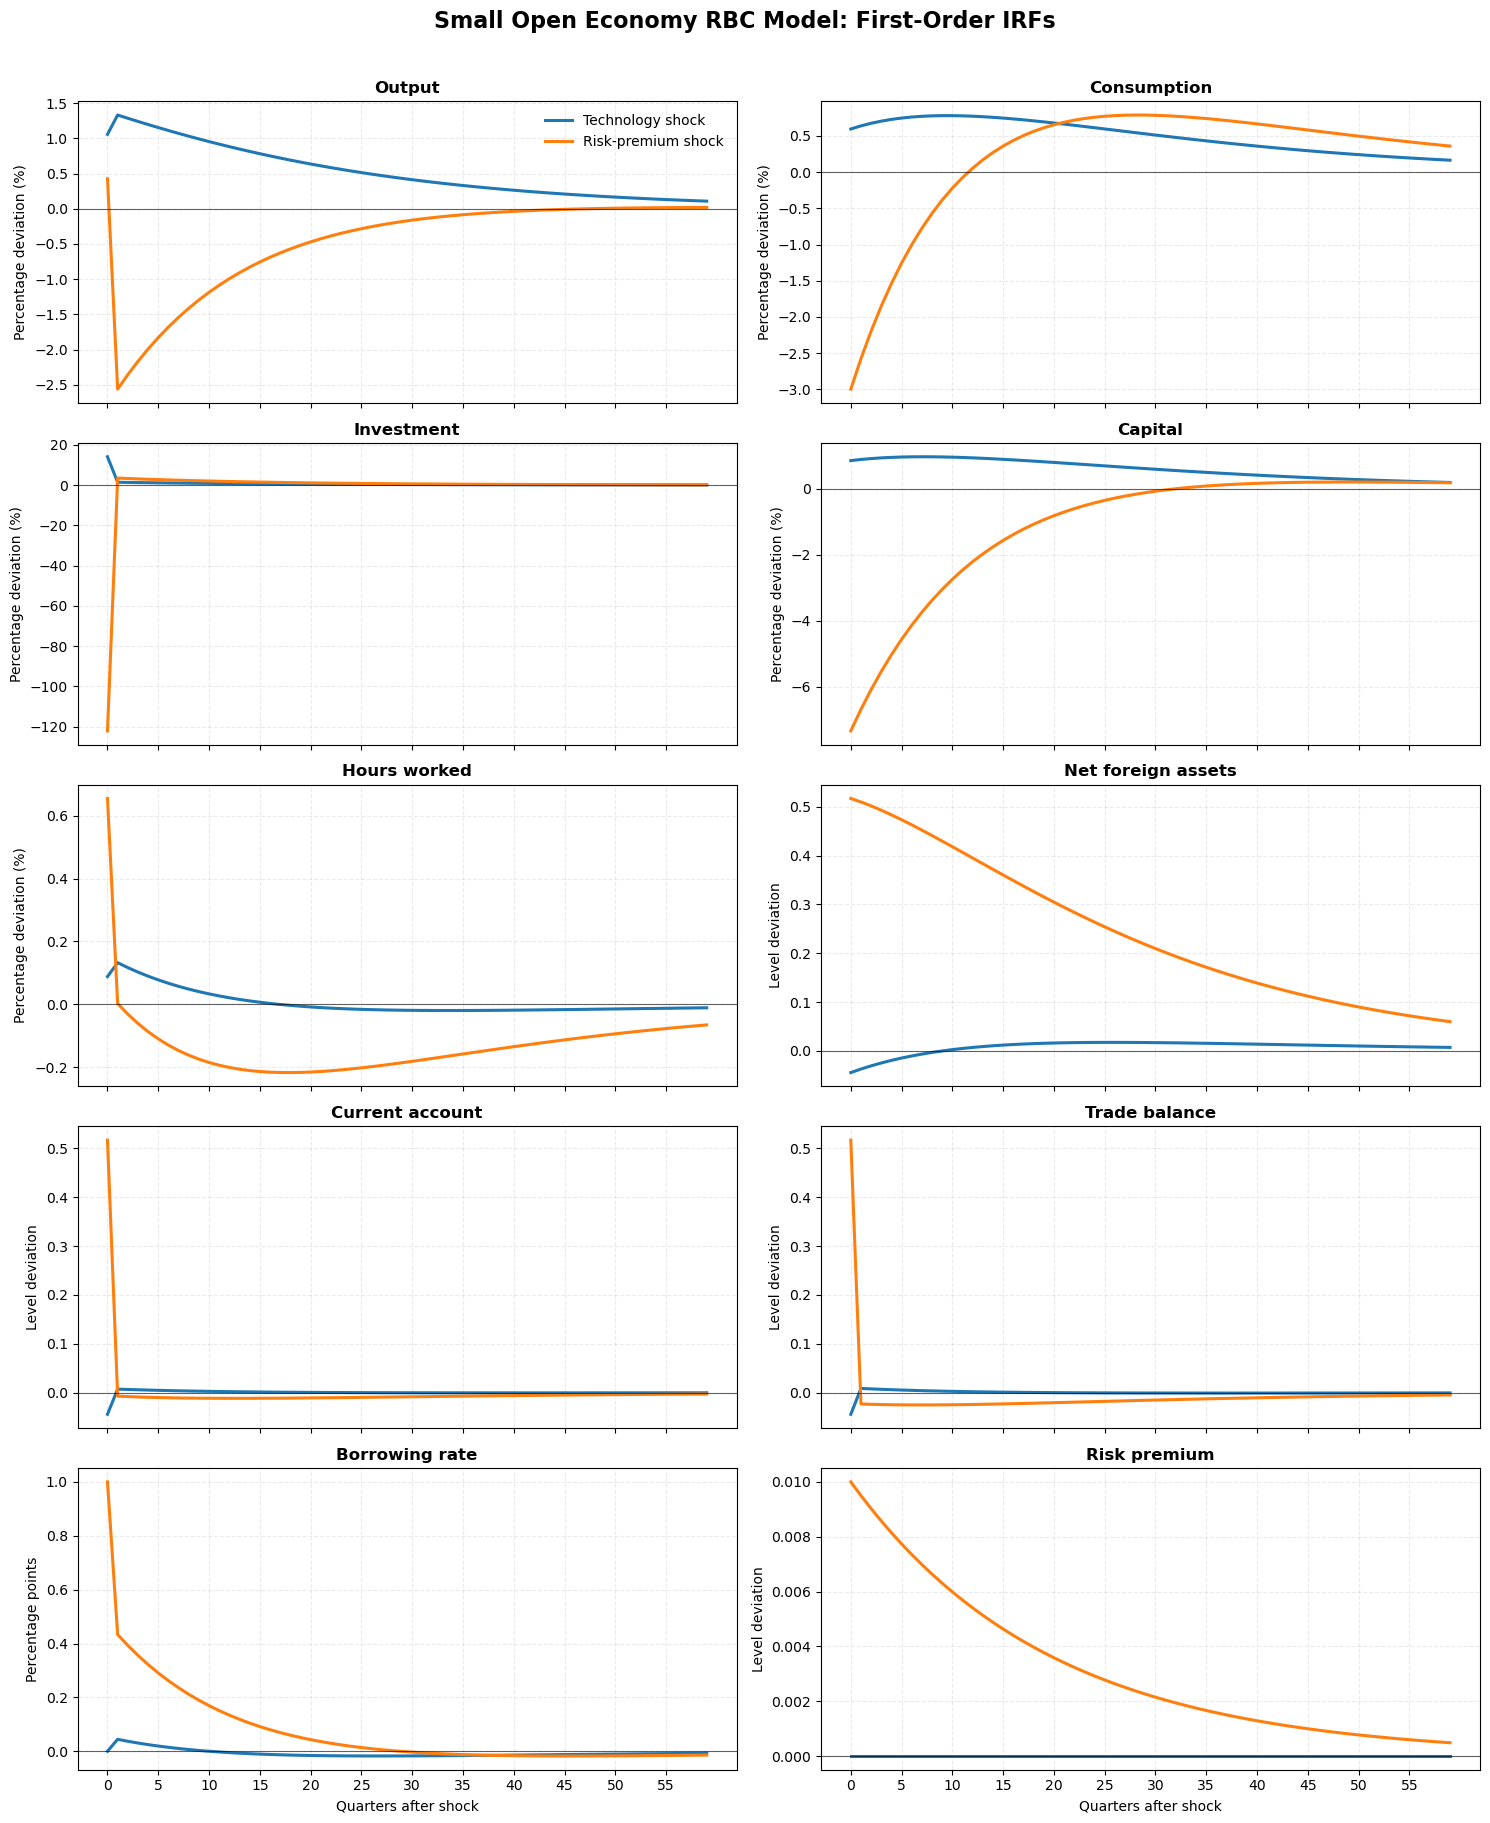


IRF SUMMARY
       Shock Variable    Impact     Peak    Trough  Quarter 10  Quarter 20  Quarter 40  Quarter 60
  Technology        y  0.017668 0.022252  0.001812    0.015951    0.010631    0.004404    0.001812
  Technology        c  0.007658 0.010027  0.002121    0.010027    0.008724    0.004622    0.002121
  Technology        i  0.054315 0.054315  0.000211    0.003233    0.001830    0.000597    0.000211
  Technology        k  0.054315 0.061773  0.011777    0.060964    0.050721    0.025993    0.011777
  Technology        h  0.000714 0.001072 -0.000158    0.000270   -0.000066   -0.000149   -0.000088
  Technology        b -0.044305 0.017517 -0.044305    0.002714    0.016244    0.013853    0.007251
  Technology       ca -0.044305 0.007240 -0.044305    0.002691    0.000562   -0.000375   -0.000287
  Technology       tb -0.044305 0.008611 -0.044305    0.002691    0.000077   -0.000815   -0.000520
  Technology       rb  0.000000 0.000443 -0.000175   -0.000000   -0.000157   -0.000142   -0.0000

In [1]:

# ================================================================
# SMALL OPEN ECONOMY RBC MODEL
# Technology and Risk-Premium Shocks
#
# Computational Macroeconomics: Lectures 18-19
# First-order solution using gEconpy Cycle Reduction
#
# Calibration and equations replicate the supplied Dynare model.
#
# Install:
# pip install numpy scipy pandas matplotlib geconpy
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from gEconpy.solvers.cycle_reduction import (
    solve_policy_function_with_cycle_reduction
)

# ================================================================
# 1. CALIBRATION
# ================================================================

alpha = 0.35
beta = 0.97
delta = 0.06
gamma = 0.20

rho_z = 0.95
rho_rp = 0.95

rstar = 1 / beta - 1

phi_b = 0.01
bbar = 0.0

sigma_z = 0.01
sigma_rp = 0.01

irf_horizon = 60

# ================================================================
# 2. STEADY STATE
# ================================================================

r_ss = rstar + delta

ky = alpha / r_ss
iy = delta * ky
cy = 1 - iy

h_ss = (1-alpha) / (1-alpha + gamma*cy)

y_ss = h_ss * ky**(alpha/(1-alpha))

k_ss = ky * y_ss
i_ss = iy * y_ss
c_ss = cy * y_ss

w_ss = (1-alpha)*y_ss/h_ss

# Variable ordering
names = [
    "y", "c", "i", "k", "h", "w", "r",
    "z", "b", "rb", "ca", "tb", "rp"
]

n = len(names)

ix = {name: j for j, name in enumerate(names)}

# Steady-state vector
ss = np.array([
    y_ss,
    c_ss,
    i_ss,
    k_ss,
    h_ss,
    w_ss,
    r_ss,
    1.0,
    bbar,
    rstar,
    0.0,
    -rstar*bbar,
    0.0
], dtype=float)


# ================================================================
# 3. MODEL EQUATIONS
#
# F(x[t-1], x[t], x[t+1], eps[t]) = 0
# ================================================================

def residual(prev, cur, nxt, shocks):

    p = prev
    x = cur
    q = nxt

    def v(arr, name):
        return arr[ix[name]]

    eps_z, eps_rp = shocks

    equations = [

        # 1. Production
        v(x, "y")
        - v(x, "z") * v(p, "k")**alpha * v(x, "h")**(1-alpha),

        # 2. Rental rate of capital
        v(x, "r")
        - alpha*v(x, "y")/v(p, "k"),

        # 3. Wage
        v(x, "w")
        - (1-alpha)*v(x, "y")/v(x, "h"),

        # 4. Capital accumulation
        v(x, "k")
        - (1-delta)*v(p, "k")
        - v(x, "i"),

        # 5. International budget constraint
        v(x, "c") + v(x, "i") + v(x, "b")
        - v(x, "y")
        - (1+v(x, "rb"))*v(p, "b"),

        # 6. Euler equation: domestic capital
        1/v(x, "c")
        - beta*(1/v(q, "c"))*(v(q, "r")+1-delta),

        # 7. Euler equation: international bond
        1/v(x, "c")
        - beta*(1/v(q, "c"))*(1+v(q, "rb")),

        # 8. Labour-leisure condition
        (1-v(x, "h"))*v(x, "w")
        - gamma*v(x, "c"),

        # 9. Technology shock
        np.log(v(x, "z"))
        - rho_z*np.log(v(p, "z"))
        - eps_z,

        # 10. Risk-premium shock
        v(x, "rp")
        - rho_rp*v(p, "rp")
        - eps_rp,

        # 11. Debt-elastic country premium
        v(x, "rb")
        - rstar
        - phi_b*(bbar-v(p, "b"))
        - v(x, "rp"),

        # 12. Current account
        v(x, "ca")
        - v(x, "b")
        + v(p, "b"),

        # 13. Trade balance
        v(x, "tb")
        - v(x, "y")
        + v(x, "c")
        + v(x, "i")
    ]

    return np.asarray(equations)


# ================================================================
# 4. STEADY-STATE VERIFICATION
# ================================================================

print("\n" + "="*60)
print("1. STEADY STATE")
print("="*60)

zero_shocks = np.zeros(2)

ss_resid = residual(ss, ss, ss, zero_shocks)

print(pd.Series(ss, index=names).round(8))

print("\nMaximum steady-state residual:",
      np.max(np.abs(ss_resid)))

if np.max(np.abs(ss_resid)) > 1e-8:
    raise RuntimeError("Steady-state verification failed.")


# ================================================================
# 5. NUMERICAL JACOBIANS
#
# A = dF/dx[t-1]
# B = dF/dx[t]
# C = dF/dx[t+1]
# D = dF/deps[t]
# ================================================================

print("\n" + "="*60)
print("2. CALCULATING JACOBIANS")
print("="*60)


def numerical_jacobian(which, step=1e-6):

    J = np.zeros((n, n))

    for j in range(n):

        d = np.zeros(n)

        h = step * max(1.0, abs(ss[j]))
        d[j] = h

        if which == "prev":

            fp = residual(ss+d, ss, ss, zero_shocks)
            fm = residual(ss-d, ss, ss, zero_shocks)

        elif which == "cur":

            fp = residual(ss, ss+d, ss, zero_shocks)
            fm = residual(ss, ss-d, ss, zero_shocks)

        elif which == "next":

            fp = residual(ss, ss, ss+d, zero_shocks)
            fm = residual(ss, ss, ss-d, zero_shocks)

        J[:, j] = (fp-fm)/(2*h)

    return J


A = numerical_jacobian("prev")
B = numerical_jacobian("cur")
C = numerical_jacobian("next")

# Shock Jacobian
D = np.zeros((n, 2))

for j in range(2):

    shock = np.zeros(2)
    shock[j] = 1e-6

    fp = residual(ss, ss, ss, shock)
    fm = residual(ss, ss, ss, -shock)

    D[:, j] = (fp-fm)/(2e-6)


print("A:", A.shape)
print("B:", B.shape)
print("C:", C.shape)
print("D:", D.shape)



# ================================================================
# 6. SOLVE USING GENSYS (QZ DECOMPOSITION)
# ================================================================

from gEconpy.solvers.gensys import (
    solve_policy_function_with_gensys,
    interpret_gensys_output
)

print("\n" + "="*60)
print("3. SOLVING MODEL USING GENSYS")
print("="*60)

solution = solve_policy_function_with_gensys(
    A, B, C, D,
    tol=1e-9,
    return_all_matrices=True
)

# GENSYS output:
# 0 = G1: augmented transition matrix
# 1 = constant vector
# 2 = shock impact matrix
# 3 = fmat
# 4 = fwt
# 5 = ywt
# 6 = generalized eigenvalues
# 7 = existence and uniqueness
# 8 = loose directions

G1 = np.asarray(solution[0])
impact = np.asarray(solution[2])
eu = solution[7]

print("Existence and uniqueness:", eu)
print(interpret_gensys_output(eu))

print("Augmented transition matrix:", G1.shape)
print("Augmented shock matrix:", impact.shape)

if eu[0] != 1 or eu[1] != 1:
    raise RuntimeError("GENSYS did not find a unique solution.")

# The augmented system includes auxiliary expectational-error
# variables. The original model variables occupy the first n rows.
P = G1[:n, :n]
R = impact[:n, :]

print("\nOriginal-variable transition block:", P.shape)
print("Original-variable shock block:", R.shape)

# ================================================================
# 7. CHECK THE SOLUTION
# ================================================================

if not np.all(np.isfinite(G1)):
    raise RuntimeError("Non-finite values in transition matrix.")

if not np.all(np.isfinite(impact)):
    raise RuntimeError("Non-finite values in shock matrix.")

# Eigenvalue diagnostics for the augmented transition matrix
eigvals = np.linalg.eigvals(G1)

print("\nMaximum absolute eigenvalue:",
      np.max(np.abs(eigvals)))

# ================================================================
# 8. GENERATE IRFs
# ================================================================

print("\n" + "="*60)
print("4. GENERATING IRFs")
print("="*60)

def generate_irf(shock_index, shock_size):

    full_irf = np.zeros((irf_horizon, G1.shape[0]))

    previous = np.zeros(G1.shape[0])

    for t in range(irf_horizon):

        eps = np.zeros(2)

        if t == 0:
            eps[shock_index] = shock_size

        current = G1 @ previous + impact @ eps

        full_irf[t, :] = current

        previous = current

    # Extract original endogenous variables
    return full_irf[:, :n]


irf_z = generate_irf(0, sigma_z)
irf_rp = generate_irf(1, sigma_rp)

print("Technology IRF:", irf_z.shape)
print("Risk-premium IRF:", irf_rp.shape)

# ================================================================
# 9. CREATE DATAFRAMES
# ================================================================

df_z = pd.DataFrame(irf_z, columns=names)
df_rp = pd.DataFrame(irf_rp, columns=names)

df_z.index.name = "Quarter"
df_rp.index.name = "Quarter"

# Percentage deviations
pct_vars = ["y", "c", "i", "k", "h", "w", "z"]

df_z_pct = df_z.copy()
df_rp_pct = df_rp.copy()

for var in pct_vars:

    df_z_pct[var] = 100 * df_z[var] / ss[ix[var]]
    df_rp_pct[var] = 100 * df_rp[var] / ss[ix[var]]

# ================================================================
# 10. PLOT IRFs
# ================================================================

plot_vars = [
    "y", "c", "i", "k", "h",
    "b", "ca", "tb", "rb", "rp"
]

titles = {
    "y": "Output",
    "c": "Consumption",
    "i": "Investment",
    "k": "Capital",
    "h": "Hours worked",
    "b": "Net foreign assets",
    "ca": "Current account",
    "tb": "Trade balance",
    "rb": "Borrowing rate",
    "rp": "Risk premium"
}

level_vars = ["b", "ca", "tb", "rb", "rp"]

fig, axes = plt.subplots(
    5, 2,
    figsize=(15, 18),
    sharex=True
)

quarters = np.arange(irf_horizon)

for j, var in enumerate(plot_vars):

    ax = axes.flat[j]

    if var in level_vars:

        z_values = df_z[var]
        rp_values = df_rp[var]

        if var == "rb":
            z_values = z_values * 100
            rp_values = rp_values * 100
            ylabel = "Percentage points"
        else:
            ylabel = "Level deviation"

    else:

        z_values = df_z_pct[var]
        rp_values = df_rp_pct[var]
        ylabel = "Percentage deviation (%)"

    ax.plot(
        quarters, z_values,
        label="Technology shock",
        linewidth=2.2
    )

    ax.plot(
        quarters, rp_values,
        label="Risk-premium shock",
        linewidth=2.2
    )

    ax.axhline(0, color="black", linewidth=0.8, alpha=0.6)

    ax.set_title(titles[var], fontsize=12, fontweight="bold")
    ax.set_ylabel(ylabel)
    ax.grid(True, linestyle="--", alpha=0.25)
    ax.set_xticks(np.arange(0, irf_horizon, 5))

    if j == 0:
        ax.legend(frameon=False)

for ax in axes[-1, :]:
    ax.set_xlabel("Quarters after shock")

fig.suptitle(
    "Small Open Economy RBC Model: First-Order IRFs",
    fontsize=16,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()

plt.savefig(
    "SOE_RBC_IRFs.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ================================================================
# 11. EXPORT RESULTS
# ================================================================

df_z.to_csv("IRF_Technology_Levels.csv")
df_rp.to_csv("IRF_RiskPremium_Levels.csv")

df_z_pct.to_csv("IRF_Technology_Percent.csv")
df_rp_pct.to_csv("IRF_RiskPremium_Percent.csv")

# ================================================================
# 12. SUMMARY TABLE
# ================================================================

summary = []

for shock_name, df in [
    ("Technology", df_z),
    ("Risk premium", df_rp)
]:

    for var in plot_vars:

        values = df[var]

        summary.append({
            "Shock": shock_name,
            "Variable": var,
            "Impact": values.iloc[0],
            "Peak": values.max(),
            "Trough": values.min(),
            "Quarter 10": values.iloc[10],
            "Quarter 20": values.iloc[20],
            "Quarter 40": values.iloc[40],
            "Quarter 60": values.iloc[59]
        })

summary_df = pd.DataFrame(summary)

print("\nIRF SUMMARY")
print(summary_df.round(6).to_string(index=False))

summary_df.to_csv("IRF_Summary.csv", index=False)

print("\nALL CALCULATIONS COMPLETED")


In [2]:
state_names = names + ["Aux_1", "Aux_2", "Aux_3"]

# Label the matrices
T_df = pd.DataFrame(
    G1,
    index=state_names,
    columns=state_names
)

R_df = pd.DataFrame(
    impact,
    index=state_names,
    columns=["Technology shock", "Risk-premium shock"]
)

# Display shock impact matrix
print("SHOCK IMPACT MATRIX (R)")
display(R_df.style.format("{:.5f}"))


SHOCK IMPACT MATRIX (R)


,Technology shock,Risk-premium shock
y,1.76683,0.71120
c,0.76584,-3.85052
i,5.43151,-47.12161
k,5.43151,-47.12161
h,0.07140,0.52952
w,1.30161,-0.30782
r,0.09615,0.03870
z,1.00000,0.00000
b,-4.43051,51.68333
rb,0.00000,1.00000


# Second Verification (Numerical)

In [3]:
# 1. Calibration
alpha = 0.35
beta = 0.97
delta = 0.06
gamma = 0.20
phi_b = 0.01
bbar = 0.0

# 2. Independently calculate steady-state values
rstar = 1 / beta - 1
r_ss = rstar + delta

ky = alpha / r_ss
iy = delta * ky
cy = 1 - iy

h_ss = (1 - alpha) / (1 - alpha + gamma * cy)
y_ss = h_ss * ky ** (alpha / (1 - alpha))

k_ss = ky * y_ss
i_ss = iy * y_ss
c_ss = cy * y_ss
w_ss = (1 - alpha) * y_ss / h_ss

# Remaining steady-state variables
z_ss = 1.0
b_ss = bbar
rp_ss = 0.0
rb_ss = rstar
ca_ss = b_ss - b_ss
tb_ss = y_ss - c_ss - i_ss

# 3. Evaluate the structural equations
# Residual = LHS - RHS

checks = {
    "Production function":
        y_ss - z_ss * k_ss**alpha * h_ss**(1-alpha),

    "Wage equation":
        w_ss - (1-alpha) * y_ss / h_ss,

    "Capital return":
        r_ss - alpha * y_ss / k_ss,

    "Capital accumulation":
        k_ss - ((1-delta)*k_ss + i_ss),

    "Resource constraint":
        -(c_ss + i_ss + b_ss) + (y_ss + (1+rb_ss)*b_ss),

    "Capital Euler equation":
        1 - beta*(r_ss + 1-delta),

    "Bond Euler equation":
        1 - beta*(1+rb_ss),

    "Labour-leisure condition":
        (1-h_ss)*w_ss - gamma*c_ss,

    "Technology process":
        np.log(z_ss) - 0.95*np.log(z_ss),

    "Risk-premium process":
        rp_ss - 0.95*rp_ss,

    "Borrowing-rate equation":
        rb_ss - (rstar + phi_b*(bbar-b_ss) + rp_ss),

    "Current account":
        ca_ss - (b_ss-b_ss),

    "Trade balance":
        tb_ss - (y_ss-c_ss-i_ss)
}

# 4. Display residuals
verification = pd.DataFrame({
    "Equation": list(checks.keys()),
    "Residual": list(checks.values())
})

verification["Absolute residual"] = verification["Residual"].abs()

print("STEADY-STATE VALUES")
print(pd.Series({
    "y": y_ss, "c": c_ss, "i": i_ss,
    "k": k_ss, "h": h_ss, "w": w_ss,
    "r": r_ss, "rb": rb_ss, "b": b_ss,
    "ca": ca_ss, "tb": tb_ss, "rp": rp_ss
}).round(6))

print("\nNUMERICAL VERIFICATION")
print(verification.to_string(index=False))

# 5. Overall numerical check
tolerance = 1e-10

if verification["Absolute residual"].max() < tolerance:
    print("\nPASS: All steady-state equations hold.")
else:
    print("\nCHECK: At least one equation has a non-negligible residual.")


STEADY-STATE VALUES
y     1.670937
c     1.285030
i     0.385907
k     6.431781
h     0.808649
w     1.343115
r     0.090928
rb    0.030928
b     0.000000
ca    0.000000
tb    0.000000
rp    0.000000
dtype: float64

NUMERICAL VERIFICATION
                Equation     Residual  Absolute residual
     Production function 2.220446e-16       2.220446e-16
           Wage equation 0.000000e+00       0.000000e+00
          Capital return 0.000000e+00       0.000000e+00
    Capital accumulation 8.881784e-16       8.881784e-16
     Resource constraint 2.220446e-16       2.220446e-16
  Capital Euler equation 0.000000e+00       0.000000e+00
     Bond Euler equation 0.000000e+00       0.000000e+00
Labour-leisure condition 0.000000e+00       0.000000e+00
      Technology process 0.000000e+00       0.000000e+00
    Risk-premium process 0.000000e+00       0.000000e+00
 Borrowing-rate equation 0.000000e+00       0.000000e+00
         Current account 0.000000e+00       0.000000e+00
           Trade bal